In [2]:

pip install torch torchvision scikit-learn pandas pillow tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Total images: 11788
Attribute matrix: (11788, 312)
Unique classes: 200
Missing attribute values: 0


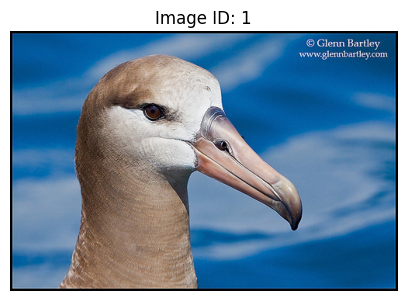

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Your existing dataset path
DATA_DIR = Path("../data/CUB_200_2011/CUB_200_2011")

# Check the dataset
assert DATA_DIR.exists(), f"Dataset not found: {DATA_DIR.resolve()}"

# Load image ID -> image path
image_paths = {}

with open(DATA_DIR / "images.txt", "r") as f:
    for line in f:
        image_id, image_path = line.strip().split(maxsplit=1)
        image_paths[int(image_id)] = image_path

# Load image ID -> class ID
image_classes = pd.read_csv(
    DATA_DIR / "image_class_labels.txt",
    sep=r"\s+",
    header=None,
    names=["image_id", "class_id"]
)

# Load attribute labels
# Use the existing dataframe if it is already in your notebook.
if "attribute_labels" not in globals():
    attribute_labels = pd.read_csv(
        DATA_DIR / "attributes" / "image_attribute_labels.txt",
        sep=r"\s+",
        header=None,
        usecols=[0, 1, 2],
        names=["image_id", "attribute_id", "is_present"],
        engine="python"
    )

# Create one row per image and one column per attribute
X_attr = attribute_labels.pivot_table(
    index="image_id",
    columns="attribute_id",
    values="is_present",
    aggfunc="first"
)

# Ensure all 312 attributes exist and are ordered correctly
X_attr = X_attr.reindex(
    index=sorted(image_paths.keys()),
    columns=range(1, 313),
    fill_value=0
).fillna(0).astype("float32")

print("Total images:", len(image_paths))
print("Attribute matrix:", X_attr.shape)
print("Unique classes:", image_classes["class_id"].nunique())
print("Missing attribute values:", int(X_attr.isna().sum().sum()))

# Display one sample image
sample_id = next(iter(image_paths))
sample_path = DATA_DIR / "images" / image_paths[sample_id]

img = Image.open(sample_path).convert("RGB")
plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.title(f"Image ID: {sample_id}")
plt.axis("off")
plt.show()

In [4]:

import torch
import torchvision
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))



PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: cpu


In [5]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import torch

# Use the same image IDs as the attribute matrix
image_ids = np.array(X_attr.index.tolist())

# 80% training, 20% validation
train_ids, val_ids = train_test_split(
    image_ids,
    test_size=0.2,
    random_state=42
)

# Image preprocessing for pretrained ResNet-18
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class CUBAttributeDataset(Dataset):
    def __init__(self, ids, image_paths, attributes, data_dir, transform):
        self.ids = list(ids)
        self.image_paths = image_paths
        self.attributes = attributes
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        image_id = self.ids[index]

        image_path = (
            self.data_dir / "images" / self.image_paths[image_id]
        )

        image = Image.open(image_path).convert("RGB")
        image = self.transform(image)

        target = self.attributes.loc[image_id].to_numpy(
            dtype=np.float32
        )

        return image, torch.tensor(target)

train_dataset = CUBAttributeDataset(
    train_ids, image_paths, X_attr, DATA_DIR, transform
)

val_dataset = CUBAttributeDataset(
    val_ids, image_paths, X_attr, DATA_DIR, transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# Test one batch
images, attributes = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Attribute batch shape:", attributes.shape)


Training images: 9430
Validation images: 2358
Image batch shape: torch.Size([32, 3, 224, 224])
Attribute batch shape: torch.Size([32, 312])


In [6]:

import torch.nn as nn
from torchvision import models

# Load pretrained ResNet-18 weights
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the original 1000-class output layer
model.fc = nn.Linear(model.fc.in_features, 312)

# Move model to CPU or GPU
model = model.to(device)

# Loss function for multi-label classification
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Model initialized successfully!")
print("Output attributes:", model.fc.out_features)
print("Device:", device)



Model initialized successfully!
Output attributes: 312
Device: cpu


In [7]:

import torch

num_epochs = 2

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )


Epoch [1/2] Train Loss: 0.2729 | Validation Loss: 0.2163
Epoch [2/2] Train Loss: 0.2072 | Validation Loss: 0.2081


In [8]:

import numpy as np
import torch
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)

        # Convert model outputs into probabilities
        logits = model(images)
        probabilities = torch.sigmoid(logits)

        all_predictions.append(probabilities.cpu().numpy())
        all_targets.append(targets.numpy())

# Combine all validation batches
y_prob = np.concatenate(all_predictions, axis=0)
y_true = np.concatenate(all_targets, axis=0).astype(int)

# Convert probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Validation images:", len(y_true))
print("Attributes per image:", y_true.shape[1])
print("Micro F1:", round(f1_score(
    y_true, y_pred, average="micro", zero_division=0
), 4))
print("Macro F1:", round(f1_score(
    y_true, y_pred, average="macro", zero_division=0
), 4))
print("Micro Precision:", round(precision_score(
    y_true, y_pred, average="micro", zero_division=0
), 4))
print("Micro Recall:", round(recall_score(
    y_true, y_pred, average="micro", zero_division=0
), 4))
print("Exact-match accuracy:", round(accuracy_score(
    y_true, y_pred
), 4))


Validation images: 2358
Attributes per image: 312
Micro F1: 0.4465
Macro F1: 0.1743
Micro Precision: 0.6814
Micro Recall: 0.332
Exact-match accuracy: 0.0


In [9]:

import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    micro_f1 = f1_score(
        y_true, predictions, average="micro", zero_division=0
    )
    macro_f1 = f1_score(
        y_true, predictions, average="macro", zero_division=0
    )
    precision = precision_score(
        y_true, predictions, average="micro", zero_division=0
    )
    recall = recall_score(
        y_true, predictions, average="micro", zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Micro F1": round(micro_f1, 4),
        "Macro F1": round(macro_f1, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

best_idx = results_df["Micro F1"].idxmax()
best_threshold = results_df.loc[best_idx, "Threshold"]

print("\nBest threshold by micro F1:", best_threshold)


 Threshold  Micro F1  Macro F1  Precision  Recall
      0.10    0.4656    0.2877     0.3208  0.8490
      0.15    0.5087    0.2840     0.3787  0.7745
      0.20    0.5325    0.2757     0.4302  0.6988
      0.25    0.5420    0.2642     0.4784  0.6251
      0.30    0.5397    0.2503     0.5244  0.5558
      0.35    0.5258    0.2327     0.5666  0.4905
      0.40    0.5051    0.2149     0.6072  0.4324
      0.45    0.4777    0.1944     0.6455  0.3792
      0.50    0.4465    0.1743     0.6814  0.3320

Best threshold by micro F1: 0.25


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the 312 official attribute names
attribute_names = {}

with open(DATA_DIR / "attributes" / "attributes.txt", "r") as f:
    for line in f:
        attr_id, attr_name = line.strip().split(maxsplit=1)
        attribute_names[int(attr_id)] = (
            attr_name.split("::")[-1]
            .replace("_", " ")
        )

# Use the best threshold found on validation data
best_threshold = 0.25

# Choose one validation image
sample_idx = 0
sample_id = int(val_ids[sample_idx])

# Get its image and labels
sample_path = DATA_DIR / "images" / image_paths[sample_id]
img = Image.open(sample_path).convert("RGB")

true_attributes = X_attr.loc[sample_id].to_numpy(dtype=int)
probabilities = y_prob[sample_idx]
predicted_attributes = probabilities >= best_threshold

# Display the bird image
plt.figure(figsize=(7, 5))
plt.imshow(img)
plt.title(f"Validation Image ID: {sample_id}")
plt.axis("off")
plt.show()

# Show the 12 attributes with the highest predicted probabilities
top_indices = np.argsort(probabilities)[::-1][:12]

comparison = pd.DataFrame({
    "Attribute": [
        attribute_names.get(i + 1, f"Attribute {i + 1}")
        for i in top_indices
    ],
    "Probability": [
        round(float(probabilities[i]), 3)
        for i in top_indices
    ],
    "Predicted": [
        "Present" if predicted_attributes[i] else "Absent"
        for i in top_indices
    ],
    "Ground truth": [
        "Present" if true_attributes[i] == 1 else "Absent"
        for i in top_indices
    ]
})

print(comparison.to_string(index=False))


FileNotFoundError: [Errno 2] No such file or directory: '..\\data\\CUB_200_2011\\CUB_200_2011\\attributes\\attributes.txt'

In [13]:

from pathlib import Path

print("Dataset directory:", DATA_DIR.resolve())

# Search for attributes.txt inside the dataset
matches = list(DATA_DIR.rglob("attributes.txt"))

if matches:
    ATTR_NAMES_PATH = matches[0]
    print("Found attribute names:", ATTR_NAMES_PATH)
else:
    print("attributes.txt was not found inside DATA_DIR.")
    print("Available files in the attributes folder:")

    attr_dir = DATA_DIR / "attributes"
    if attr_dir.exists():
        for path in attr_dir.iterdir():
            print(path.name)
    else:
        print("Attributes folder not found:", attr_dir)



Dataset directory: C:\Users\S SHREYAS KUMAR\Downloads\BirdSpeciesML\data\CUB_200_2011\CUB_200_2011


attributes.txt was not found inside DATA_DIR.
Available files in the attributes folder:
certainties.txt
class_attribute_labels_continuous.txt
image_attribute_labels.txt


In [15]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\S SHREYAS KUMAR\Downloads\BirdSpeciesML")

matches = list(PROJECT_DIR.rglob("attributes.txt"))

if matches:
    ATTR_NAMES_PATH = matches[0]
    print("Found:", ATTR_NAMES_PATH)
else:
    print("attributes.txt is not present anywhere in the project.")
    

Found: C:\Users\S SHREYAS KUMAR\Downloads\BirdSpeciesML\data\CUB_200_2011\attributes.txt


In [17]:
# Load attribute names
attribute_names = {}

with open(ATTR_NAMES_PATH, "r") as f:
    for line in f:
        attr_id, attr_name = line.strip().split(maxsplit=1)
        attribute_names[int(attr_id)] = (
            attr_name.split("::")[-1].replace("_", " ")
        )

print("Total attributes:", len(attribute_names))
print("First 10 attributes:")

for attr_id in range(1, 11):
    print(f"{attr_id}: {attribute_names[attr_id]}")

Total attributes: 312
First 10 attributes:
1: curved (up or down)
2: dagger
3: hooked
4: needle
5: hooked seabird
6: spatulate
7: all-purpose
8: cone
9: specialized
10: blue


In [20]:
import matplotlib.pyplot as plt
import torch
from PIL import Image

# Select a validation sample
sample_idx = 0
sample_id = int(val_ids[sample_idx])

# Get image and actual attribute labels
image_tensor, actual_attributes = val_dataset[sample_idx]

# Get predicted probabilities from the trained model
model.eval()
with torch.no_grad():
    logits = model(image_tensor.unsqueeze(0).to(device))
    predicted_probs = torch.sigmoid(logits).cpu().numpy()[0]

actual_attributes = actual_attributes.numpy()

# Find the 12 attributes with highest predicted probabilities
top_indices = predicted_probs.argsort()[-12:][::-1]

# Load the original image
image_path = DATA_DIR.parent / image_paths[sample_id]
original_image = Image.open(image_path).convert("RGB")

# Plot image and attribute predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(original_image)
axes[0].set_title(f"Validation Image (ID: {sample_id})")
axes[0].axis("off")

names = [attribute_names[i + 1] for i in top_indices]
probabilities = predicted_probs[top_indices]

bars = axes[1].barh(names[::-1], probabilities[::-1])
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Predicted Probability")
axes[1].set_title("Top 12 Predicted Attributes")

for bar, idx in zip(bars, top_indices[::-1]):
    actual = int(actual_attributes[idx])
    axes[1].text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"Actual: {actual}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '..\\data\\CUB_200_2011\\137.Cliff_Swallow\\Cliff_Swallow_0092_132971.jpg'